# HW9｜站點坡度與地形

1. 讀懂 GeoTIFF 的中繼資料：CRS、解析度、範圍、nodata。
2. 在以公尺為單位的網格上計算坡度，並能確認單位正確。
3. 把站點和 DEM 的 CRS 對齊後取樣，並驗證取樣到的數值合理。
4. 說明 20 公尺 DEM 能看到什麼、看不到什麼

## 0. 路徑與中文字型

沿用 `00_Colab環境設定範本.ipynb` 的兩個儲存格。本週多了三個路徑：鄉鎮市區界、老師的備援快照，以及你自己從 TDX 抓下來的資料。

In [34]:
import sys
import urllib.request
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib import font_manager

"""路徑設定"""
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/115-1_GISprog")

    """安裝相關套件"""
    %pip install -q mapclassify
    %pip install -q rioxarray mapclassify
else:
    # 備援：本機執行時，notebook 位於 115-1_GISprog/notebooks/，上一層就是專案資料夾
    PROJECT_DIR = Path.cwd().parent

print("執行環境：", "Google Colab" if IN_COLAB else "本機")

"""字型設定"""
FONT_DIR = PROJECT_DIR / "fonts"
FONT_URL = "https://drive.google.com/uc?id=1eGAsTN1HBpJAkeVM57_C7ccp7hbgSz3_&export=download"
FONT_PATH = FONT_DIR / "TaipeiSansTCBeta-Regular.ttf"

if not FONT_PATH.exists():
    FONT_DIR.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(FONT_URL, FONT_PATH)

font_manager.fontManager.addfont(str(FONT_PATH))     # 告訴 Matplotlib：「這個字型檔可以使用」
plt.rcParams["font.family"] = "Taipei Sans TC Beta"  # 指定之後畫圖預設使用這個中文字型
plt.rcParams["axes.unicode_minus"] = False           # 避免負號 − 顯示異常
print("已設定中文字型：", FONT_PATH.name)

執行環境： 本機
已設定中文字型： TaipeiSansTCBeta-Regular.ttf


## 1. 選縣市、準備資料

1. 選一個縣市。建議沿用 HW6、HW7 的縣市，站點直接讀你存在 `data/raw/tdx/` 的快照。
   * 臺中市是課堂範例，請選其他縣市。
   * 想改用期末專題的範圍也可以，但老師只裁切了 W6 站點 API 的 15 個縣市：臺北市、新北市、桃園市、臺中市、臺南市、高雄市、新竹市、新竹縣、苗栗縣、彰化縣、雲林縣、嘉義縣、嘉義市、屏東縣、臺東縣。

2. 從老師分享的雲端資料夾 `dem20m_2026` 下載你的縣市的 DEM，上傳到 `115-1_GISprog/data/raw/dem20m_2026/`。檔名是 `dem20m_{縣市代碼}.tif`，代碼和站點快照相同，例如 `dem20m_Kaohsiung.tif`、
`dem20m_PingtungCounty.tif`。
1. 在 `notebooks/` 建立 `09_station_terrain.ipynb`。可以請 agent 參考課堂的 `09_網格資料與地形.ipynb` 撰寫，但每一步的結果都要自己檢查。這份作業不需要呼叫 TDX API。 筆記表頭的「本次 API 呼叫次數與扣點」寫 0 次；如果你重新抓了站點，寫實際次數。


In [35]:
CITY = "NewTaipei" 
CITY_DICT = {
                "Taipei": "臺北市", "NewTaipei": "新北市", "Taoyuan": "桃園市", "Taichung": "臺中市", "Tainan": "臺南市",
                "Kaohsiung": "高雄市", "Hsinchu": "新竹市", "HsinchuCounty": "新竹縣", "MiaoliCounty": "苗栗縣", "ChanghuaCounty": "彰化縣",
                "YunlinCounty": "雲林縣", "ChiayiCounty": "嘉義縣", "Chiayi": "嘉義市", "PingtungCounty": "屏東縣", "TaitungCounty": "臺東縣"
            }    

if CITY_DICT.get(CITY) == None:
    raise ValueError("CITY 的值錯誤，請確認選擇的程式代號是否輸入正確")
else:
    print("所選縣市：" + str(CITY_DICT.get(CITY)))

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FONT_DIR = PROJECT_DIR / "fonts"

DEM_TIF = RAW_DIR / "dem20m_2026" / f"dem20m_{CITY}.tif"              # 內政部 20 m DEM（臺中市）
TOWN_SHP = RAW_DIR / "Taiwan_boundaries" / "Town" / "Taiwan_town.shp"  # 鄉鎮市區界
BIKE_BACKUP = RAW_DIR / "tdx_station_20261012"                         # W6 站點備援快照

for p in [DEM_TIF, TOWN_SHP, BIKE_BACKUP]:
    if not p.exists():
        raise FileNotFoundError(f"找不到 {p}，請依課前準備上傳")

print(f"預備檔案：dem20m_2026_{CITY}.tif、Taiwan_town.shp、tdx_station_20261012 資料夾讀取成功")

所選縣市：新北市
預備檔案：dem20m_2026_NewTaipei.tif、Taiwan_town.shp、tdx_station_20261012 資料夾讀取成功


## 2. 讀取 DEM 的中繼資料
1. 用 `rasterio` 打開你的縣市的 DEM，印出 CRS、解析度、範圍與 nodata。
2. 用 `rioxarray.open_rasterio(..., masked=True)` 讀成 DataArray，印出最低與最高的高程，用常識檢查：最低的地方應該接近海平面，最高的地方對得上你的縣市（或鄰近縣市）的高山嗎？
3. 寫下不加 `masked=True` 時，最低值是多少、為什麼。

In [36]:
import numpy as np
import rasterio
import rioxarray
import xarray as xr

"""讀取縣市資料"""
src = rasterio.open(DEM_TIF)
print("讀取縣市資料")
print("\tCRS\t：", src.crs, "｜單位：", src.crs.linear_units)
print("\t解析度\t：", src.res)
print("\t範圍\t：", src.bounds)
print("\tnodata\t：", src.nodata, "｜資料型態：", src.dtypes[0])

"""印出高程"""
dem = rioxarray.open_rasterio(DEM_TIF, masked=True).squeeze("band", drop=True)
print("\n高程")
print("\t最低\t：", round(float(dem.min()), 2))
print("\t最高\t：", round(float(dem.max()), 2))

"""不加 masked=True 的最低值"""
origin = rioxarray.open_rasterio(DEM_TIF).squeeze("band", drop=True) 
print("\n不加 masked=True")
print("\t最低\t：", round(float(origin.min()), 2))

讀取縣市資料
	CRS	： EPSG:3826 ｜單位： metre
	解析度	： (20.0, 20.0)
	範圍	： BoundingBox(left=277490.0, bottom=2728670.0, right=351670.0, top=2799170.0)
	nodata	： -32767.0 ｜資料型態： float32

高程
	最低	： -14.24
	最高	： 2128.46

不加 masked=True
	最低	： -32767.0


**回答補充說明**(回答編號對應題目編號)：  

2. 依據[臺灣山林優活網](https://recreation.forest.gov.tw/Trail/RT?tr_id=034)的說明，塔曼山為新北市第一高峰，海拔 2130 公尺，與最高的格子 2128.46 公尺相近；依據[維基百科](https://zh.wikipedia.org/zh-tw/%E8%98%86%E6%B4%B2%E5%8D%80)說明，新北市蘆洲區的海拔僅有 1 公尺，與最低的格子 -14.24 有一點落差，可能是 DEM 的誤差所造成。
3. 不加 `masked=True` 的最低值為 -32767.0 ，用來表示該區塊為 nodata。

## 3. 計算坡度
1. 用 `np.gradient` 計算坡度，單位為度。網格大小要從 `dem.rio.resolution()` 取得，並印出它的單位。
2. 先在整張 DEM 上算坡度，再裁切到你的縣市（`rio.clip`）。
3. 常識檢查：挑一個你熟悉的平地（例如市中心的一個區），印出坡度的中位數，應該接近 0 度；再挑一個山區比較。

網格大小： 20.0 metre
坡度： 0.0 ～ 79.56 度
裁切前： (3525, 3709) → 裁切後： (3474, 3658)


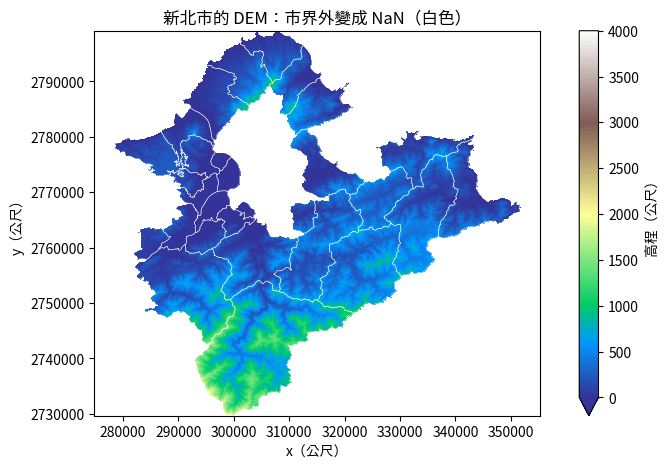

,區,高程中位數_m,坡度中位數_度,百分比
0,蘆洲區,1.4,0.6,1.1
1,三重區,2.5,0.5,0.9
2,永和區,7.3,0.6,1.0
3,板橋區,6.8,0.6,1.1
4,三峽區,362.7,26.6,50.1
5,烏來區,853.2,34.7,69.3


In [37]:
import geopandas as gpd
import pandas as pd

"""計算坡度"""
net = abs(dem.rio.resolution()[0])
print("網格大小：", net, dem.rio.crs.linear_units)

dz_dy, dz_dx = np.gradient(dem.values, net)                              # 第 0 軸南北、第 1 軸東西
slope = dem.copy(data=np.degrees(np.arctan(np.hypot(dz_dx, dz_dy))))
del dz_dy, dz_dx                                                         # 中間結果用完就刪，Colab 記憶體比較寬裕
print("坡度：", round(float(slope.min()), 2), "～", round(float(slope.max()), 2), "度")

"""裁切到縣市"""
town = gpd.read_file(TOWN_SHP)
city = town[town["COUNTYNAME"] == CITY_DICT.get(CITY)]
dem_clip = dem.rio.clip(city.geometry, crs=city.crs)
print("裁切前：", dem.shape, "→ 裁切後：", dem_clip.shape)

fig, ax = plt.subplots(figsize=(10, 5))
dem_clip.plot.imshow(ax=ax, cmap="terrain", vmin=0, vmax=4000, cbar_kwargs={"label": "高程（公尺）"})
city.boundary.plot(ax=ax, color="white", linewidth=0.3)
ax.set_title(CITY_DICT.get(CITY) + "的 DEM：市界外變成 NaN（白色）")
ax.set(xlabel="x（公尺）", ylabel="y（公尺）", aspect="equal")
ax.ticklabel_format(style="plain")
plt.show()

"""常識檢查"""
area = ["蘆洲區", "三重區", "永和區", "板橋區", "三峽區", "烏來區"]
area_clip = lambda array, name: float(array.rio.clip(city[city["TOWNNAME"] == name].geometry, crs=city.crs).median())
sense = pd.DataFrame({"區": a, "高程中位數_m": area_clip(dem, a), "坡度中位數_度": area_clip(slope, a), "百分比": (np.tan(np.radians(area_clip(slope, a))) * 100).round(1)} for a in area).round(1) 
display(sense)

**回答補充說明**(回答編號對應題目編號)：  

3. 根據網路搜尋資料，蘆洲區、三重區、永和區、板橋區為平地區域；三峽區和烏來區為山地區域，與常識檢查內容符合

## 4. 在站點取樣
1. 站點轉成和 DEM 相同的 CRS，印出兩者的 EPSG 代碼確認一致。
2. 用 `sel(..., method="nearest")` 一次取樣全部站點的高程與坡度。
3. 檢查：取不到值（NaN）的站點有幾個？為什麼？
4. 驗證取樣結果，至少做一種：
    * 用另一種方法（例如 rasterio 的 src.sample）取同幾個站點，數值相同。
    * 挑 2–3 個你知道地形的站點（海邊、河邊、山坡、台地），高程合理。
5. 比較單點取樣與周圍平均（例如周圍 5 × 5 格）的坡度，找出差最多的站點，在地圖上看看旁邊是什麼。

In [38]:
import json

"""轉成 DEM 的 CRS"""
def read_station(code):
    """讀 W6 的站點備援快照，回傳 GeoDataFrame（EPSG:4326）。HW9：改讀你自己的快照。"""
    df = pd.json_normalize(json.loads((BIKE_BACKUP / f"station_{code}.json").read_text(encoding="utf-8")))
    df = df.rename(columns={"StationName.Zh_tw": "站點名稱"})
    return gpd.GeoDataFrame(
        df[["StationUID", "StationID", "站點名稱"]],
        geometry=gpd.points_from_xy(df["StationPosition.PositionLon"], df["StationPosition.PositionLat"]),
        crs="EPSG:4326",
    )


station_4326 = read_station(CITY)
station = station_4326.to_crs(dem.rio.crs)      # 先轉成 DEM 的 CRS
print(CITY_DICT.get(CITY) + "站點數量：", len(station), "站；站點 EPSG:", station.crs.to_epsg(), "｜DEM EPSG:", dem.rio.crs.to_epsg())

"""一次取樣全部站點"""
x = xr.DataArray(station.geometry.x.values, dims="站點")
y = xr.DataArray(station.geometry.y.values, dims="站點")
station["高程_m"] = dem.sel(x=x, y=y, method="nearest").values
station["坡度_度"] = slope.sel(x=x, y=y, method="nearest").values
display(station[["站點名稱", "高程_m", "坡度_度"]].head())

"""檢查"""
print(CITY_DICT.get(CITY) + "取到", len(station), "個值；高程是 NaN 的站：", station["高程_m"].isna().sum(), "；坡度是 NaN 的站：", station["坡度_度"].isna().sum())

"""兩種驗證"""
top5 = station.head(5)
sample = [v[0] for v in src.sample(zip(top5.geometry.x, top5.geometry.y))]
print("src.sample：", np.round(sample, 2))
print("sel       ：", top5["高程_m"].round(2).values)

location = ["YouBike2.0_烏來老街", "YouBike2.0_坪林茶業博物館", "YouBike2.0_猴硐火車站", "YouBike2.0_輕軌淡江大學站"]
display(station.set_index("站點名稱").loc[location, ["高程_m", "坡度_度"]].round(2))

"""比較單點取樣與平均"""
dev = [-40, -20, 0, 20, 40]                     # 周圍 5 × 5 格，約 100 × 100 公尺
nearby = [slope.sel(x=x + dx, y=y + dy, method="nearest").values for dx in dev for dy in dev]
station["坡度_周圍平均"] = np.nanmean(nearby, axis=0)
station["單點減周圍"] = station["坡度_度"] - station["坡度_周圍平均"]

row = ["站點名稱", "坡度_度", "坡度_周圍平均", "單點減周圍"]
print("單點比周圍大最多：")
display(station.nlargest(3, "單點減周圍")[row].round(2))
print("單點比周圍小最多：")
display(station.nsmallest(3, "單點減周圍")[row].round(2))

新北市站點數量： 1614 站；站點 EPSG: 3826 ｜DEM EPSG: 3826


,站點名稱,高程_m,坡度_度
0,YouBike2.0_下庄市場,6.42,0.726116
1,YouBike2.0_八里行政中心,7.19,1.185348
2,YouBike2.0_八里中庄市場綜合大樓,4.50,2.371453
3,YouBike2.0_大崁國小,3.62,3.051707
4,YouBike2.0_龍形停車場,7.45,2.888362


新北市取到 1614 個值；高程是 NaN 的站： 0 ；坡度是 NaN 的站： 0
src.sample： [6.42 7.19 4.5  3.62 7.45]
sel       ： [6.42 7.19 4.5  3.62 7.45]


,高程_m,坡度_度
站點名稱,,
YouBike2.0_烏來老街,117.529999,15.81
YouBike2.0_坪林茶業博物館,192.220001,3.77
YouBike2.0_猴硐火車站,94.779999,0.73
YouBike2.0_輕軌淡江大學站,71.889999,3.92


單點比周圍大最多：


,站點名稱,坡度_度,坡度_周圍平均,單點減周圍
576,YouBike2.0_石碇,28.709999,17.280001,11.43
1232,YouBike2.0_輕軌耕莘安康院區站,18.690001,7.320000,11.37
261,YouBike2.0_橫溪橋,18.180000,8.840000,9.34


單點比周圍小最多：


,站點名稱,坡度_度,坡度_周圍平均,單點減周圍
1132,YouBike2.0_獅子公園,3.04,17.860001,-14.82
1144,YouBike2.0_猴硐遊客中心,10.11,21.590000,-11.48
579,YouBike2.0_菁桐老街,8.01,19.180000,-11.17


**回答補充說明**(回答編號對應題目編號)：  

4. 根據 AI 的判讀，烏來老街沿著南勢溪的河岸坡地；坪林茶葉博物館的高程最高，但位在北勢溪旁的河階平地，坡度小；猴硐火車站基隆河谷底的車站，幾乎是平的；輕軌淡江大學站在淡金路上、校園所在丘陵的山腳，不在校園的坡上
5. 根據 Google Map 搜尋結果與程式結果比對，石碇站在石碇溪旁邊、輕軌耕莘安康院區站位在一個斜坡、橫溪橋位在橫溪旁邊，因此上述三個站單點坡度會比周圍來的大；獅子公園再山腳下、猴硐遊客中心如上題所述、菁桐老街也位在山腳下，因此這三個站點單點坡度筆周圍來的小

## 5. 地圖與各區比較
1. 畫地形暈渲圖或坡度圖，疊上站點（依坡度著色或分級），要有中文標題與圖例。
2. 用 `sjoin` 得到每個站點所在的鄉鎮市區，比較各區站點的高程分布（表格加上盒鬚圖或長條圖）。
3. 用 `explore()` 疊在臺灣通用電子地圖上，目視檢查坡度最大的 2–3 個站點。

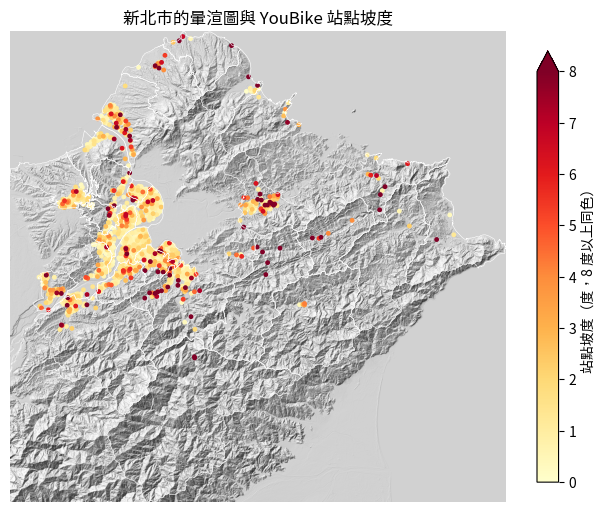

新北市 1614 站；沒有配對到鄉鎮市區的站： 0


,站數,高程中位數,坡度中位數,坡度超過5度
鄉鎮市區,,,,
蘆洲區,55,1.300000,0.800000,3
三重區,141,2.400000,0.600000,2
五股區,31,3.900000,0.900000,5
新莊區,142,4.000000,0.700000,3
金山區,9,4.100000,1.000000,2
泰山區,26,6.000000,0.700000,3
八里區,32,6.000000,0.800000,2
板橋區,224,6.800000,0.600000,5
石門區,5,7.100000,6.800000,3


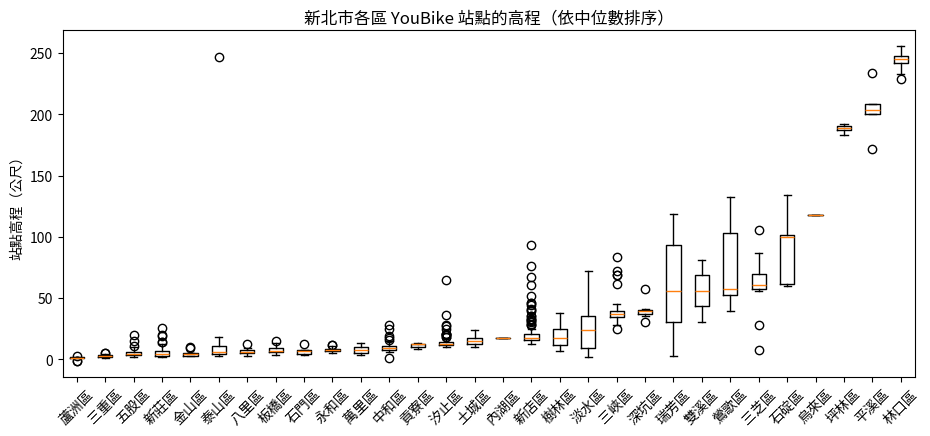

In [42]:
from matplotlib.colors import LightSource

"""暈渲圖與 YouBike 站點坡度"""
xmin, ymin, xmax, ymax = city.total_bounds
XL, YL = (xmin, xmax), (ymin, ymax)
son = dem.sel(x=slice(*XL), y=slice(YL[1], YL[0]))     # y 由北往南排，slice 要從大到小
shade = LightSource(azdeg=315, altdeg=45).hillshade(np.nan_to_num(son.values), vert_exag=2, dx=net, dy=net)
scope = [float(son.x.min()) - 10, float(son.x.max()) + 10, float(son.y.min()) - 10, float(son.y.max()) + 10]

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(shade, cmap="gray", extent=scope)
city.boundary.plot(ax=ax, color="white", linewidth=0.4)
sort = station.sort_values("坡度_度")                       # 陡的站最後畫，才不會被蓋住
point = ax.scatter(sort.geometry.x, sort.geometry.y, c=sort["坡度_度"], cmap="YlOrRd", vmin=0, vmax=8, s=6)
plt.colorbar(point, ax=ax, label="站點坡度（度，8 度以上同色）", shrink=0.7, extend="max")
ax.set_xlim(*XL)
ax.set_ylim(*YL)
ax.set_title(CITY_DICT.get(CITY) + "的暈渲圖與 YouBike 站點坡度")
ax.set_axis_off()
plt.show()

"""各站點高程分佈"""
station_town = gpd.sjoin(station, town[["TOWNNAME", "geometry"]], how="left", predicate="within").drop(columns="index_right")
station_town = station_town.rename(columns={"TOWNNAME": "鄉鎮市區"})
print(CITY_DICT.get(CITY), len(station_town), "站；沒有配對到鄉鎮市區的站：", station_town["鄉鎮市區"].isna().sum())

town_area = (station_town.groupby("鄉鎮市區")
          .agg(站數=("StationUID", "size"), 高程中位數=("高程_m", "median"), 坡度中位數=("坡度_度", "median"),
               坡度超過5度=("坡度_度", lambda s: int((s > 5).sum())))
          .sort_values("高程中位數")
          .round(1))
display(town_area)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.boxplot([station_town.loc[station_town["鄉鎮市區"] == i, "高程_m"] for i in town_area.index], tick_labels=town_area.index)
ax.set_ylabel("站點高程（公尺）")
ax.set_title(CITY_DICT.get(CITY) + "各區 YouBike 站點的高程（依中位數排序）")
ax.tick_params(axis="x", labelrotation=45)
plt.show()

"""explore 檢查"""
station_town.explore(
    column="坡度_度", cmap="YlOrRd", vmin=0, vmax=8,
    tooltip=["站點名稱", "鄉鎮市區", "高程_m", "坡度_度", "坡度_周圍平均"],
    marker_kwds={"radius": 4},
    tiles="https://wmts.nlsc.gov.tw/wmts/EMAP/default/GoogleMapsCompatible/{z}/{y}/{x}",
    attr="臺灣通用電子地圖 © 內政部國土測繪中心",
)

## 6. 存檔（HW10 會用到）

把站點存成 GPKG 到 `data/processed/`，至少包含 StationUID、站名、所在鄉鎮市區、高程、坡度。**HW10 會用 StationUID 合併即時的可借車數**，不要刪掉這一欄。

In [40]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FILENAME = "w9_" + str(CITY) + "_terrain.gpkg"
GPKG = PROCESSED_DIR / FILENAME
save_row = ["StationUID", "StationID", "站點名稱", "鄉鎮市區", "高程_m", "坡度_度", "坡度_周圍平均", "geometry"]
station_town[save_row].to_file(GPKG, layer="stations", driver="GPKG")
print("已存：", GPKG.name)
display(gpd.read_file(GPKG).head(10))

已存： w9_NewTaipei_terrain.gpkg


,StationUID,StationID,站點名稱,鄉鎮市區,高程_m,坡度_度,坡度_周圍平均,geometry
0,NWT500201001,500201001,YouBike2.0_下庄市場,八里區,6.42,0.726116,0.653569,POINT (2.9e+05 2.78e+06)
1,NWT500201002,500201002,YouBike2.0_八里行政中心,八里區,7.19,1.185348,0.931148,POINT (2.91e+05 2.78e+06)
2,NWT500201003,500201003,YouBike2.0_八里中庄市場綜合大樓,八里區,4.50,2.371453,1.723856,POINT (2.92e+05 2.78e+06)
3,NWT500201004,500201004,YouBike2.0_大崁國小,八里區,3.62,3.051707,1.648556,POINT (2.92e+05 2.78e+06)
4,NWT500201006,500201006,YouBike2.0_龍形停車場,八里區,7.45,2.888362,3.060327,POINT (2.96e+05 2.78e+06)
5,NWT500201007,500201007,YouBike2.0_十三行博物館,八里區,5.96,0.234929,1.358043,POINT (2.91e+05 2.78e+06)
6,NWT500201008,500201008,YouBike2.0_八里區民活動中心,八里區,5.53,0.404375,1.329910,POINT (2.9e+05 2.78e+06)
7,NWT500201009,500201009,YouBike2.0_挖仔尾自然生態保留區,八里區,3.04,1.935594,1.243113,POINT (2.92e+05 2.78e+06)
8,NWT500201010,500201010,YouBike2.0_文昌公園,八里區,6.85,0.405388,0.666444,POINT (2.91e+05 2.78e+06)
9,NWT500201011,500201011,YouBike2.0_八里國小,八里區,6.63,0.077136,1.398986,POINT (2.91e+05 2.78e+06)
